# 🧠 Parkinson's Disease Detection using Deep Learning
**Dhwani Jain, Himanshu, Dev — Bennett University**

Multimodal pipeline combining two data modalities:
- **Module 1** — Voice Biomarkers (tabular CSV) → Logistic Regression, SVM, Random Forest, ANN
- **Module 2** — Spiral Drawings (images) → CNN-inspired feature extraction + Deep MLP
- **Module 3** — Final comparison dashboard

## ⚙️ Setup & Imports

In [1]:
# Install missing packages if running in Colab
import subprocess, sys
try:
    from imblearn.over_sampling import SMOTE
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])

import os, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

try:
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True
except ImportError:
    HAS_SMOTE = False

warnings.filterwarnings("ignore")
np.random.seed(42)
%matplotlib inline
plt.rcParams['figure.dpi'] = 120

print("✅ All imports successful")
print(f"   SMOTE available: {HAS_SMOTE}")


✅ All imports successful
   SMOTE available: True


## 📂 Upload Datasets
> Upload `parkinsons.csv` and `spiral.zip` using the cell below, or place them at the paths shown.

In [2]:
# ── Option A: Colab file upload ──────────────────────────────────────────────
try:
    from google.colab import files
    print("Running in Colab — use the upload widget below if files are not yet uploaded.")
    # Uncomment to trigger upload dialog:
    # uploaded = files.upload()
except ImportError:
    print("Not in Colab — make sure parkinsons.csv and spiral.zip are in the working directory.")

# ── Resolve file paths ───────────────────────────────────────────────────────
import os
def find_file(name):
    """Search common locations for an uploaded file."""
    candidates = [
        f"/content/{name}",
        f"./{name}",
        os.path.join(os.getcwd(), name),
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"'{name}' not found. Please upload it first.")

CSV_PATH    = find_file("parkinsons.csv")
ZIP_PATH    = find_file("spiral.zip")
SPIRAL_DIR  = "/content/spiral_data"

print(f"✅ parkinsons.csv → {CSV_PATH}")
print(f"✅ spiral.zip     → {ZIP_PATH}")


Running in Colab — use the upload widget below if files are not yet uploaded.
✅ parkinsons.csv → /content/parkinsons.csv
✅ spiral.zip     → /content/spiral.zip


## 📊 Module 1 — Voice Biomarker Dataset
### 1.1 Exploratory Data Analysis

In [3]:
df = pd.read_csv(CSV_PATH)

print(f"Shape         : {df.shape}")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicates    : {df.duplicated().sum()}")
print()
print("Class distribution (status):")
print(df["status"].value_counts().rename({0: "Healthy (0)", 1: "Parkinson (1)"}))
print()
print("Feature statistics:")
df.drop(columns=["name","status"]).describe().round(4)


Shape         : (195, 24)
Missing values: 0
Duplicates    : 0

Class distribution (status):
status
Parkinson (1)    147
Healthy (0)       48
Name: count, dtype: int64

Feature statistics:


,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,MDVP:APQ,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE
count,195.0000,195.0000,195.0000,195.0000,195.0000,195.0000,195.0000,195.0000,195.0000,195.0000,...,195.0000,195.0000,195.0000,195.0000,195.0000,195.0000,195.0000,195.0000,195.0000,195.0000
mean,154.2286,197.1049,116.3246,0.0062,0.0000,0.0033,0.0034,0.0099,0.0297,0.2823,...,0.0241,0.0470,0.0248,21.8860,0.4985,0.7181,-5.6844,0.2265,2.3818,0.2066
std,41.3901,91.4915,43.5214,0.0048,0.0000,0.0030,0.0028,0.0089,0.0189,0.1949,...,0.0169,0.0305,0.0404,4.4258,0.1039,0.0553,1.0902,0.0834,0.3828,0.0901
min,88.3330,102.1450,65.4760,0.0017,0.0000,0.0007,0.0009,0.0020,0.0095,0.0850,...,0.0072,0.0136,0.0006,8.4410,0.2566,0.5743,-7.9650,0.0063,1.4233,0.0445
25%,117.5720,134.8625,84.2910,0.0035,0.0000,0.0017,0.0019,0.0050,0.0165,0.1485,...,0.0131,0.0247,0.0059,19.1980,0.4213,0.6748,-6.4501,0.1744,2.0991,0.1375
50%,148.7900,175.8290,104.3150,0.0049,0.0000,0.0025,0.0027,0.0075,0.0230,0.2210,...,0.0183,0.0384,0.0117,22.0850,0.4960,0.7223,-5.7209,0.2189,2.3615,0.1941
75%,182.7690,224.2055,140.0185,0.0074,0.0001,0.0038,0.0040,0.0115,0.0379,0.3500,...,0.0294,0.0608,0.0256,25.0755,0.5876,0.7619,-5.0462,0.2792,2.6365,0.2530
max,260.1050,592.0300,239.1700,0.0332,0.0003,0.0214,0.0196,0.0643,0.1191,1.3020,...,0.1378,0.1694,0.3148,33.0470,0.6852,0.8253,-2.4340,0.4505,3.6712,0.5274


### 1.2 Preprocessing — Scaling & Class Balancing

In [4]:
df.drop_duplicates(inplace=True)
X = df.drop(columns=["name", "status"]).values
y = df["status"].values

# MinMax scaling
scaler  = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Class balancing: SMOTE if available, else random oversampling
if HAS_SMOTE:
    sm = SMOTE(random_state=42)
    X_bal, y_bal = sm.fit_resample(X_scaled, y)
    print("✅ SMOTE applied")
else:
    def random_oversample(X, y):
        idx_min = np.where(y == y[np.argmin(np.bincount(y))])[0]
        n_extra = np.bincount(y).max() - len(idx_min)
        extra   = np.random.choice(idx_min, size=n_extra, replace=True)
        return np.vstack([X, X[extra]]), np.concatenate([y, y[extra]])
    X_bal, y_bal = random_oversample(X_scaled, y)
    print("ℹ️  Random oversampling applied (install imbalanced-learn for SMOTE)")

print(f"After balancing — Healthy: {(y_bal==0).sum()}, Parkinson: {(y_bal==1).sum()}")

X_train, X_test, y_train, y_test = train_test_split(
    X_bal, y_bal, test_size=0.2, random_state=42, stratify=y_bal)
print(f"Train: {X_train.shape[0]}  |  Test: {X_test.shape[0]}")


✅ SMOTE applied
After balancing — Healthy: 147, Parkinson: 147
Train: 235  |  Test: 59


### 1.3 Classical ML Models — LR, SVM, Random Forest

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "SVM (RBF)":           SVC(kernel="rbf", probability=True, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=42),
}

ml_results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    acc    = accuracy_score(y_test, y_pred)
    auc    = roc_auc_score(y_test, y_prob)
    ml_results[name] = {"model": model, "acc": acc, "auc": auc,
                        "y_pred": y_pred, "y_prob": y_prob}
    print(f"  {name:<22} Acc={acc:.4f}  AUC={auc:.4f}")


  Logistic Regression    Acc=0.8644  AUC=0.9161
  SVM (RBF)              Acc=0.8814  AUC=0.9552
  Random Forest          Acc=0.9831  AUC=1.0000


### 1.4 ANN Model — Multi-Layer Perceptron (128 → 64 → 32)

In [6]:
ann = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu", solver="adam",
    alpha=1e-4, batch_size=32,
    max_iter=300, random_state=42,
    early_stopping=True, validation_fraction=0.15,
    n_iter_no_change=20,
)
ann.fit(X_train, y_train)

y_pred_ann = ann.predict(X_test)
y_prob_ann = ann.predict_proba(X_test)[:, 1]
acc_ann    = accuracy_score(y_test, y_pred_ann)
auc_ann    = roc_auc_score(y_test, y_prob_ann)
ml_results["ANN (MLP)"] = {"model": ann, "acc": acc_ann, "auc": auc_ann,
                            "y_pred": y_pred_ann, "y_prob": y_prob_ann}

print(f"ANN — Acc={acc_ann:.4f}  AUC={auc_ann:.4f}")
print()
print(classification_report(y_test, y_pred_ann, target_names=["Healthy", "Parkinson"]))


ANN — Acc=0.8983  AUC=0.9713

              precision    recall  f1-score   support

     Healthy       0.85      0.97      0.91        30
   Parkinson       0.96      0.83      0.89        29

    accuracy                           0.90        59
   macro avg       0.91      0.90      0.90        59
weighted avg       0.91      0.90      0.90        59



### 1.5 Voice Dataset — Visualisations

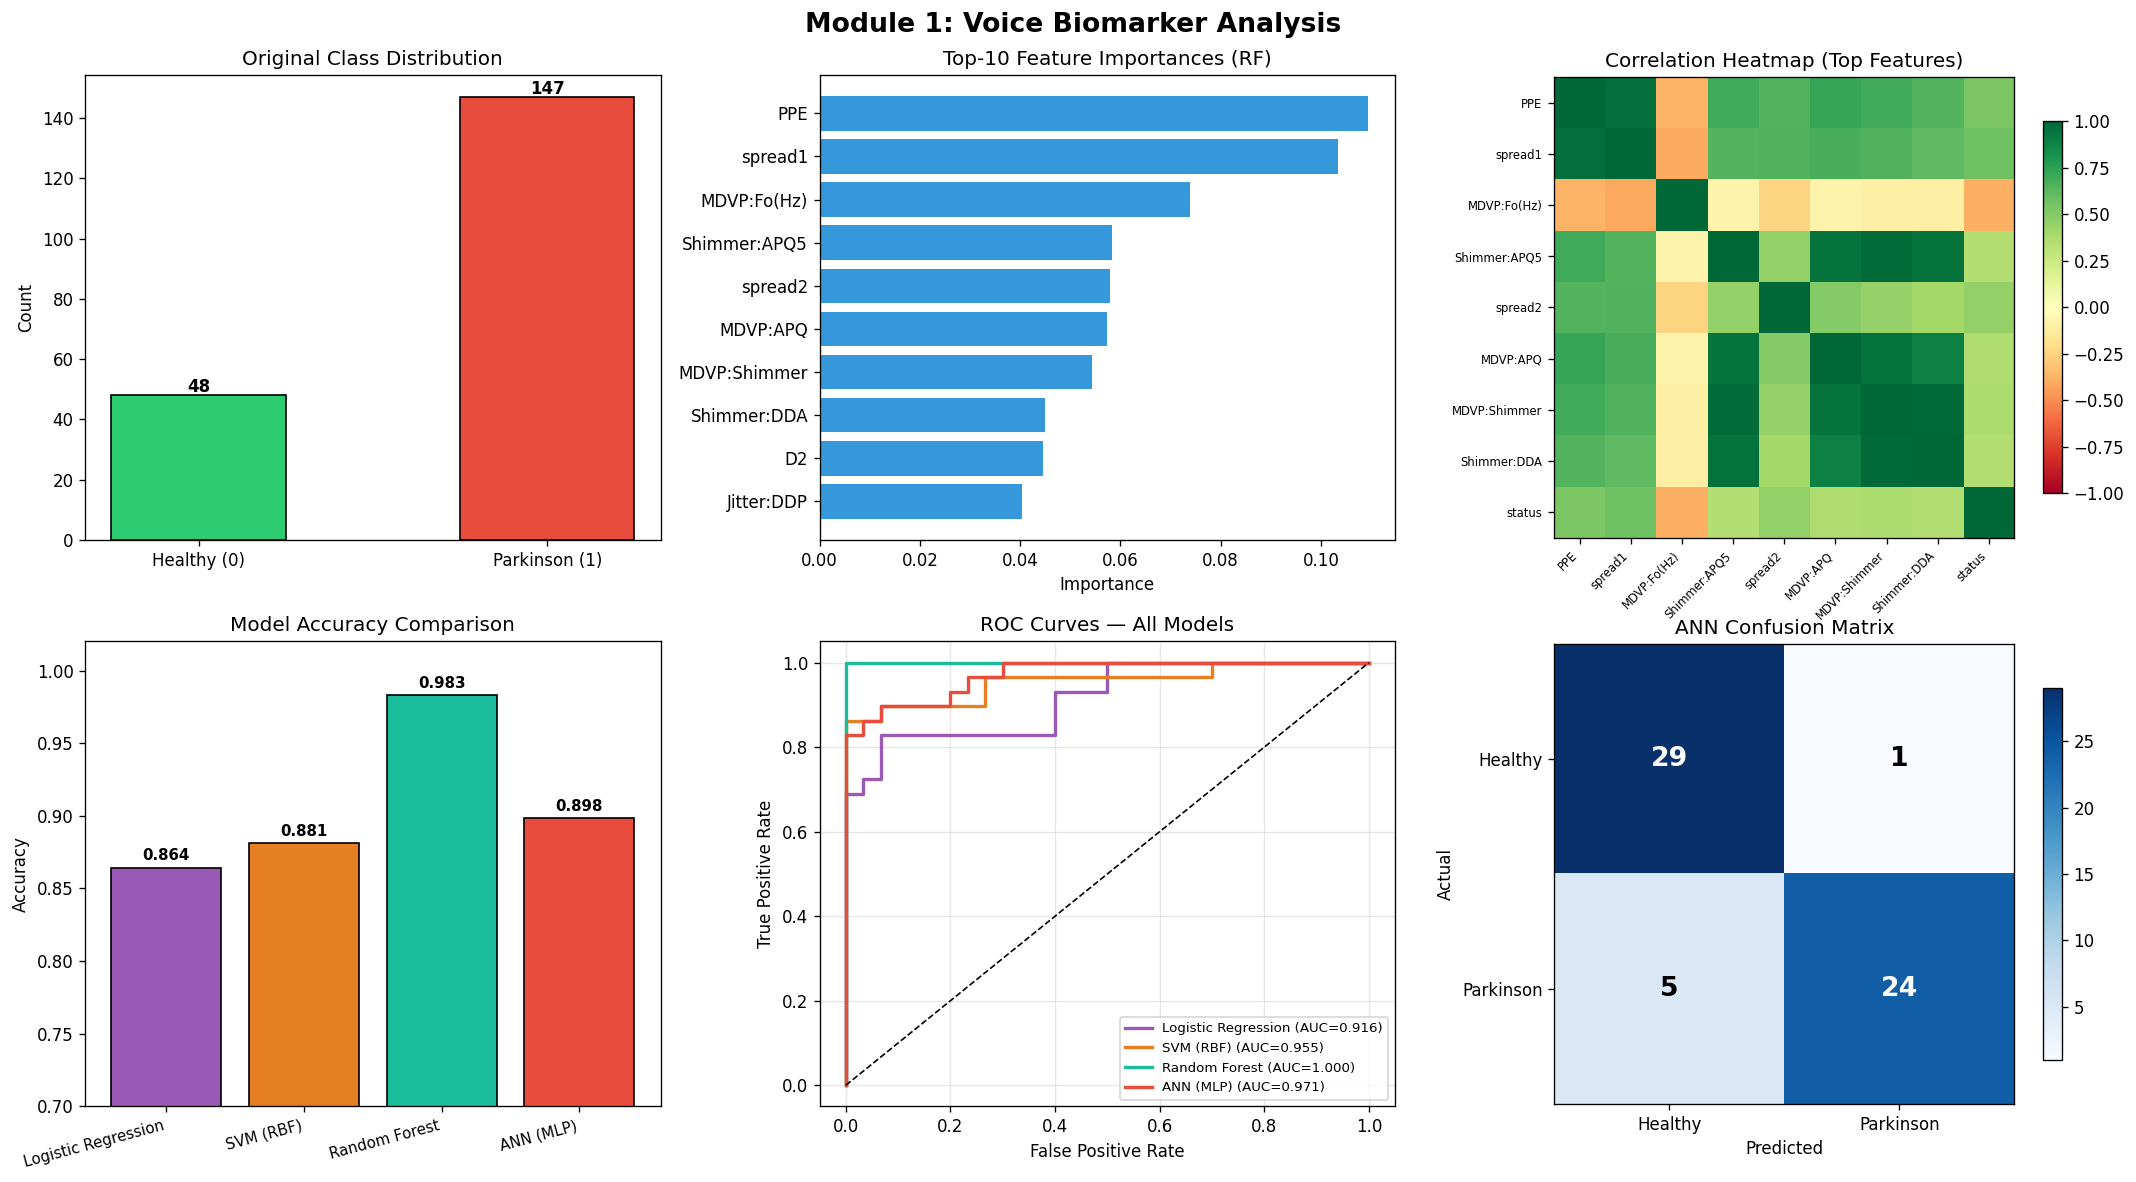

In [7]:
feat_names  = df.drop(columns=["name", "status"]).columns.tolist()
importances = ml_results["Random Forest"]["model"].feature_importances_
top_idx     = np.argsort(importances)[::-1][:10]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Module 1: Voice Biomarker Analysis", fontsize=16, fontweight="bold")

# ── Class distribution ────────────────────────────────────────────────────────
ax = axes[0, 0]
orig_counts = [(y == 0).sum(), (y == 1).sum()]
bars = ax.bar(["Healthy (0)", "Parkinson (1)"], orig_counts,
              color=["#2ecc71", "#e74c3c"], edgecolor="black", width=0.5)
ax.set_title("Original Class Distribution")
ax.set_ylabel("Count")
for i, v in enumerate(orig_counts):
    ax.text(i, v + 1, str(v), ha="center", fontweight="bold")

# ── Feature importance ────────────────────────────────────────────────────────
ax = axes[0, 1]
ax.barh([feat_names[i] for i in top_idx], importances[top_idx], color="#3498db")
ax.set_title("Top-10 Feature Importances (RF)")
ax.set_xlabel("Importance")
ax.invert_yaxis()

# ── Correlation heatmap ───────────────────────────────────────────────────────
ax = axes[0, 2]
top_feats = [feat_names[i] for i in top_idx[:8]]
corr_data = df[top_feats + ["status"]].corr()
im = ax.imshow(corr_data.values, cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_data.columns)))
ax.set_yticks(range(len(corr_data.columns)))
ax.set_xticklabels(corr_data.columns, rotation=45, ha="right", fontsize=7)
ax.set_yticklabels(corr_data.columns, fontsize=7)
plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation Heatmap (Top Features)")

# ── Model accuracy comparison ─────────────────────────────────────────────────
ax = axes[1, 0]
model_names = list(ml_results.keys())
accs = [ml_results[m]["acc"] for m in model_names]
bars = ax.bar(model_names, accs,
              color=["#9b59b6", "#e67e22", "#1abc9c", "#e74c3c"], edgecolor="black")
ax.set_ylim(0.7, 1.02)
ax.set_title("Model Accuracy Comparison")
ax.set_ylabel("Accuracy")
ax.set_xticklabels(model_names, rotation=15, ha="right", fontsize=9)
for bar, v in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.005, f"{v:.3f}",
            ha="center", fontsize=9, fontweight="bold")

# ── ROC Curves ────────────────────────────────────────────────────────────────
ax = axes[1, 1]
for (name, res), c in zip(ml_results.items(),
                          ["#9b59b6", "#e67e22", "#1abc9c", "#e74c3c"]):
    fpr, tpr, _ = roc_curve(y_test, res["y_prob"])
    ax.plot(fpr, tpr, label=f"{name} (AUC={res['auc']:.3f})", color=c, lw=2)
ax.plot([0,1],[0,1],"k--",lw=1)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — All Models")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# ── ANN Confusion Matrix ──────────────────────────────────────────────────────
ax = axes[1, 2]
cm = confusion_matrix(y_test, y_pred_ann)
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0,1]); ax.set_yticks([0,1])
ax.set_xticklabels(["Healthy","Parkinson"])
ax.set_yticklabels(["Healthy","Parkinson"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("ANN Confusion Matrix")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i,j]), ha="center", va="center",
                fontsize=16, fontweight="bold",
                color="white" if cm[i,j] > cm.max()/2 else "black")
plt.colorbar(im, ax=ax, shrink=0.8)

plt.tight_layout()
plt.show()


---
## 🌀 Module 2 — Spiral Drawing Dataset
### 2.1 Extract ZIP & Load Images

In [8]:
# Extract ZIP (skip macOS junk files)
if not os.path.exists(SPIRAL_DIR):
    print("Extracting spiral.zip ...")
    with zipfile.ZipFile(ZIP_PATH) as z:
        members = [m for m in z.namelist()
                   if not m.startswith("__MACOSX") and ".DS_Store" not in m]
        z.extractall(SPIRAL_DIR, members=members)
    print("Done.")
else:
    print("Already extracted.")

IMG_SIZE  = (64, 64)
LABEL_MAP = {"healthy": 0, "parkinson": 1}

def load_images(base_dir, split):
    X_imgs, y_imgs = [], []
    split_dir = os.path.join(base_dir, "spiral", split)
    for label_name, label_int in LABEL_MAP.items():
        folder = os.path.join(split_dir, label_name)
        if not os.path.isdir(folder):
            continue
        for fname in sorted(os.listdir(folder)):
            if not fname.lower().endswith(".png"):
                continue
            img = Image.open(os.path.join(folder, fname)).convert("RGB").resize(IMG_SIZE)
            X_imgs.append(np.array(img, dtype=np.float32) / 255.0)
            y_imgs.append(label_int)
    return np.array(X_imgs), np.array(y_imgs)

X_img_train, y_img_train = load_images(SPIRAL_DIR, "training")
X_img_test,  y_img_test  = load_images(SPIRAL_DIR, "testing")

print(f"Training: {X_img_train.shape}  →  {dict(zip(['Healthy','Parkinson'], np.bincount(y_img_train)))}")
print(f"Testing : {X_img_test.shape}   →  {dict(zip(['Healthy','Parkinson'], np.bincount(y_img_test)))}")


Extracting spiral.zip ...
Done.
Training: (72, 64, 64, 3)  →  {'Healthy': np.int64(36), 'Parkinson': np.int64(36)}
Testing : (30, 64, 64, 3)   →  {'Healthy': np.int64(15), 'Parkinson': np.int64(15)}


### 2.2 Sample Spiral Images

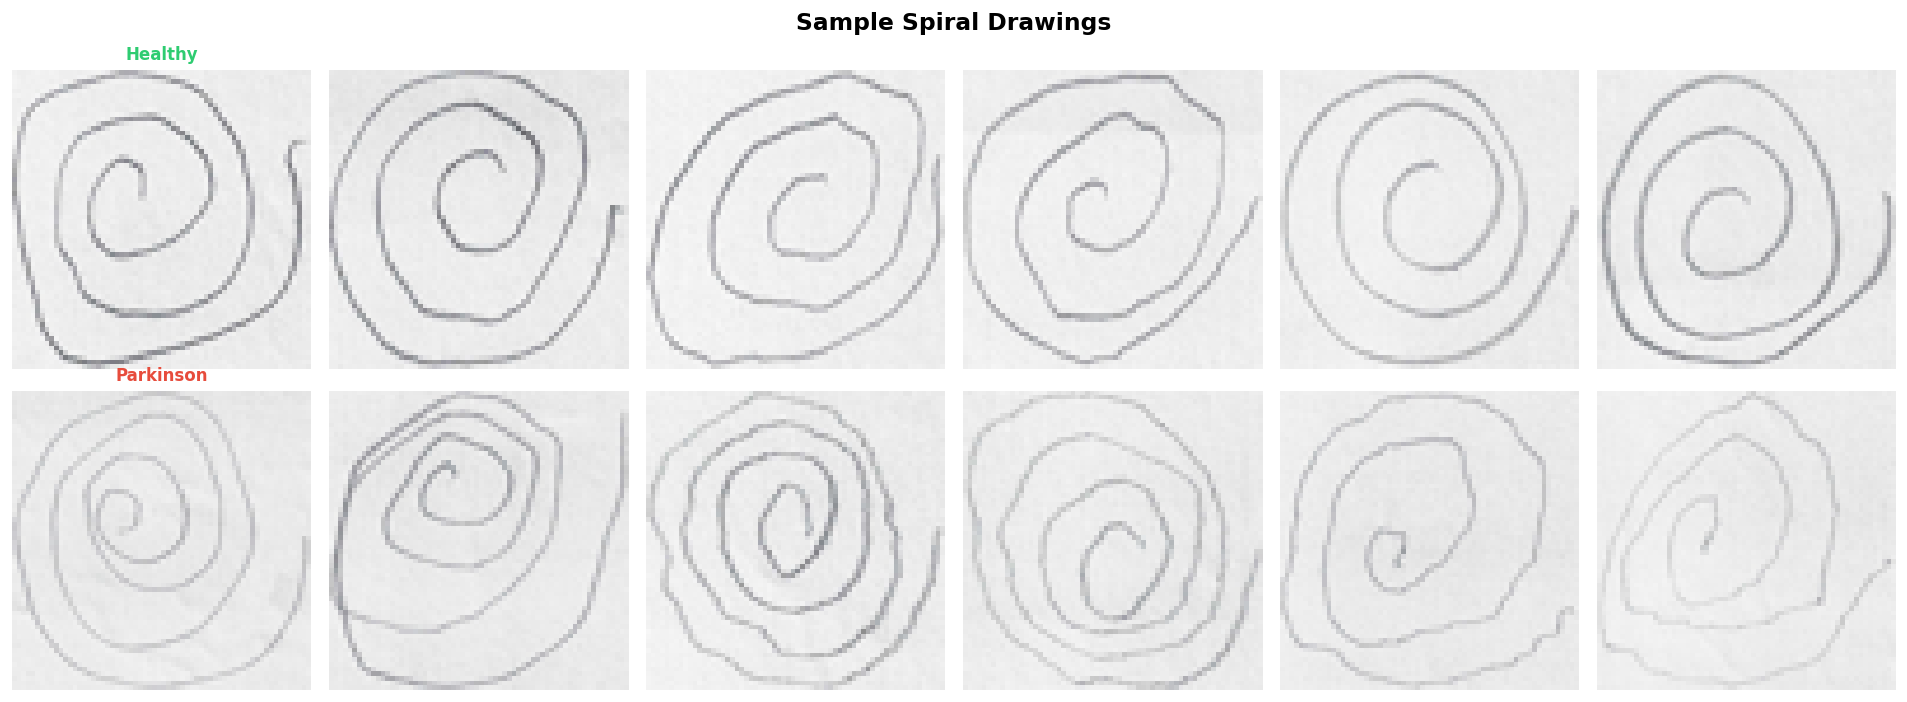

In [9]:
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
fig.suptitle("Sample Spiral Drawings", fontsize=14, fontweight="bold")

for row, (label, label_int) in enumerate([("Healthy", 0), ("Parkinson", 1)]):
    idxs = np.where(y_img_train == label_int)[0][:6]
    for col, idx in enumerate(idxs):
        axes[row, col].imshow(X_img_train[idx])
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(label, fontsize=10, fontweight="bold",
                                     color="#2ecc71" if label_int==0 else "#e74c3c")

plt.tight_layout()
plt.show()


### 2.3 CNN-Inspired Feature Extraction
Applies 8 hand-crafted convolutional filters (Sobel edges, Laplacian, diagonals) with ReLU + max pooling — then feeds the compact feature vectors into a deep MLP.

In [10]:
def extract_cnn_features(images):
    """
    Simulates a CNN feature extractor:
      8 filters (3×3) → ReLU → 4×4 MaxPool → statistical summary
    Returns a compact feature vector per image.
    """
    filters = np.array([
        [[-1,0,1],[-2,0,2],[-1,0,1]],     # Sobel-x
        [[-1,-2,-1],[0,0,0],[1,2,1]],      # Sobel-y
        [[0,1,0],[1,-4,1],[0,1,0]],        # Laplacian
        [[1,0,-1],[0,0,0],[-1,0,1]],       # Diagonal
        [[-1,0,1],[0,0,0],[1,0,-1]],       # Anti-diagonal
        [[1,1,1],[0,0,0],[-1,-1,-1]],      # Horizontal edge
        [[1,0,-1],[1,0,-1],[1,0,-1]],      # Vertical edge
        [[0,-1,0],[-1,5,-1],[0,-1,0]],     # Sharpening
    ], dtype=np.float32)

    features = []
    for img in images:
        gray = img.mean(axis=2).astype(np.float32)
        H, W = gray.shape
        feat_vec = []

        for filt in filters:
            conv = np.zeros((H-2, W-2), dtype=np.float32)
            for di in range(3):
                for dj in range(3):
                    conv += gray[di:H-2+di, dj:W-2+dj] * filt[di, dj]
            conv = np.maximum(0, conv)   # ReLU
            ps = 4
            ph, pw = conv.shape[0]//ps, conv.shape[1]//ps
            pooled = conv[:ph*ps, :pw*ps].reshape(ph, ps, pw, ps).max(axis=(1, 3))
            feat_vec += [pooled.mean(), pooled.std(), pooled.max(),
                         np.percentile(pooled, 25), np.percentile(pooled, 75)]

        feat_vec += [gray.mean(), gray.std(),
                     np.percentile(gray, 10), np.percentile(gray, 90)]
        for c in range(3):
            feat_vec += [img[:,:,c].mean(), img[:,:,c].std()]

        gx = np.zeros((H-2, W-2), dtype=np.float32)
        gy = np.zeros((H-2, W-2), dtype=np.float32)
        for di in range(3):
            for dj in range(3):
                gx += gray[di:H-2+di, dj:W-2+dj] * filters[0][di, dj]
                gy += gray[di:H-2+di, dj:W-2+dj] * filters[1][di, dj]
        mag = np.sqrt(gx**2 + gy**2)
        feat_vec += [mag.mean(), mag.std(), mag.max()]
        features.append(feat_vec)

    return np.array(features, dtype=np.float32)

print("Extracting features from training images ...")
X_cnn_train = extract_cnn_features(X_img_train)
print("Extracting features from testing images ...")
X_cnn_test  = extract_cnn_features(X_img_test)
print(f"Feature vector size: {X_cnn_train.shape[1]} per image")

cnn_scaler    = MinMaxScaler()
X_cnn_train_s = cnn_scaler.fit_transform(X_cnn_train)
X_cnn_test_s  = cnn_scaler.transform(X_cnn_test)


Extracting features from training images ...
Extracting features from testing images ...
Feature vector size: 53 per image


### 2.4 Train Deep MLP on CNN Features

In [11]:
cnn_mlp = MLPClassifier(
    hidden_layer_sizes=(256, 128, 64, 32),
    activation="relu", solver="adam",
    alpha=1e-3, batch_size=16,
    max_iter=500, random_state=42,
    early_stopping=True, validation_fraction=0.2,
    n_iter_no_change=30, learning_rate_init=0.001,
)
cnn_mlp.fit(X_cnn_train_s, y_img_train)

y_cnn_pred    = cnn_mlp.predict(X_cnn_test_s)
y_cnn_prob    = cnn_mlp.predict_proba(X_cnn_test_s)[:, 1]
cnn_acc       = accuracy_score(y_img_test, y_cnn_pred)
cnn_auc       = roc_auc_score(y_img_test, y_cnn_prob)
cnn_loss_hist = cnn_mlp.loss_curve_

print(f"CNN-MLP — Acc={cnn_acc:.4f}  AUC={cnn_auc:.4f}")
print()
print(classification_report(y_img_test, y_cnn_pred, target_names=["Healthy", "Parkinson"]))


CNN-MLP — Acc=0.5667  AUC=0.6667

              precision    recall  f1-score   support

     Healthy       0.55      0.73      0.63        15
   Parkinson       0.60      0.40      0.48        15

    accuracy                           0.57        30
   macro avg       0.57      0.57      0.55        30
weighted avg       0.57      0.57      0.55        30



### 2.5 Spiral CNN — Visualisations

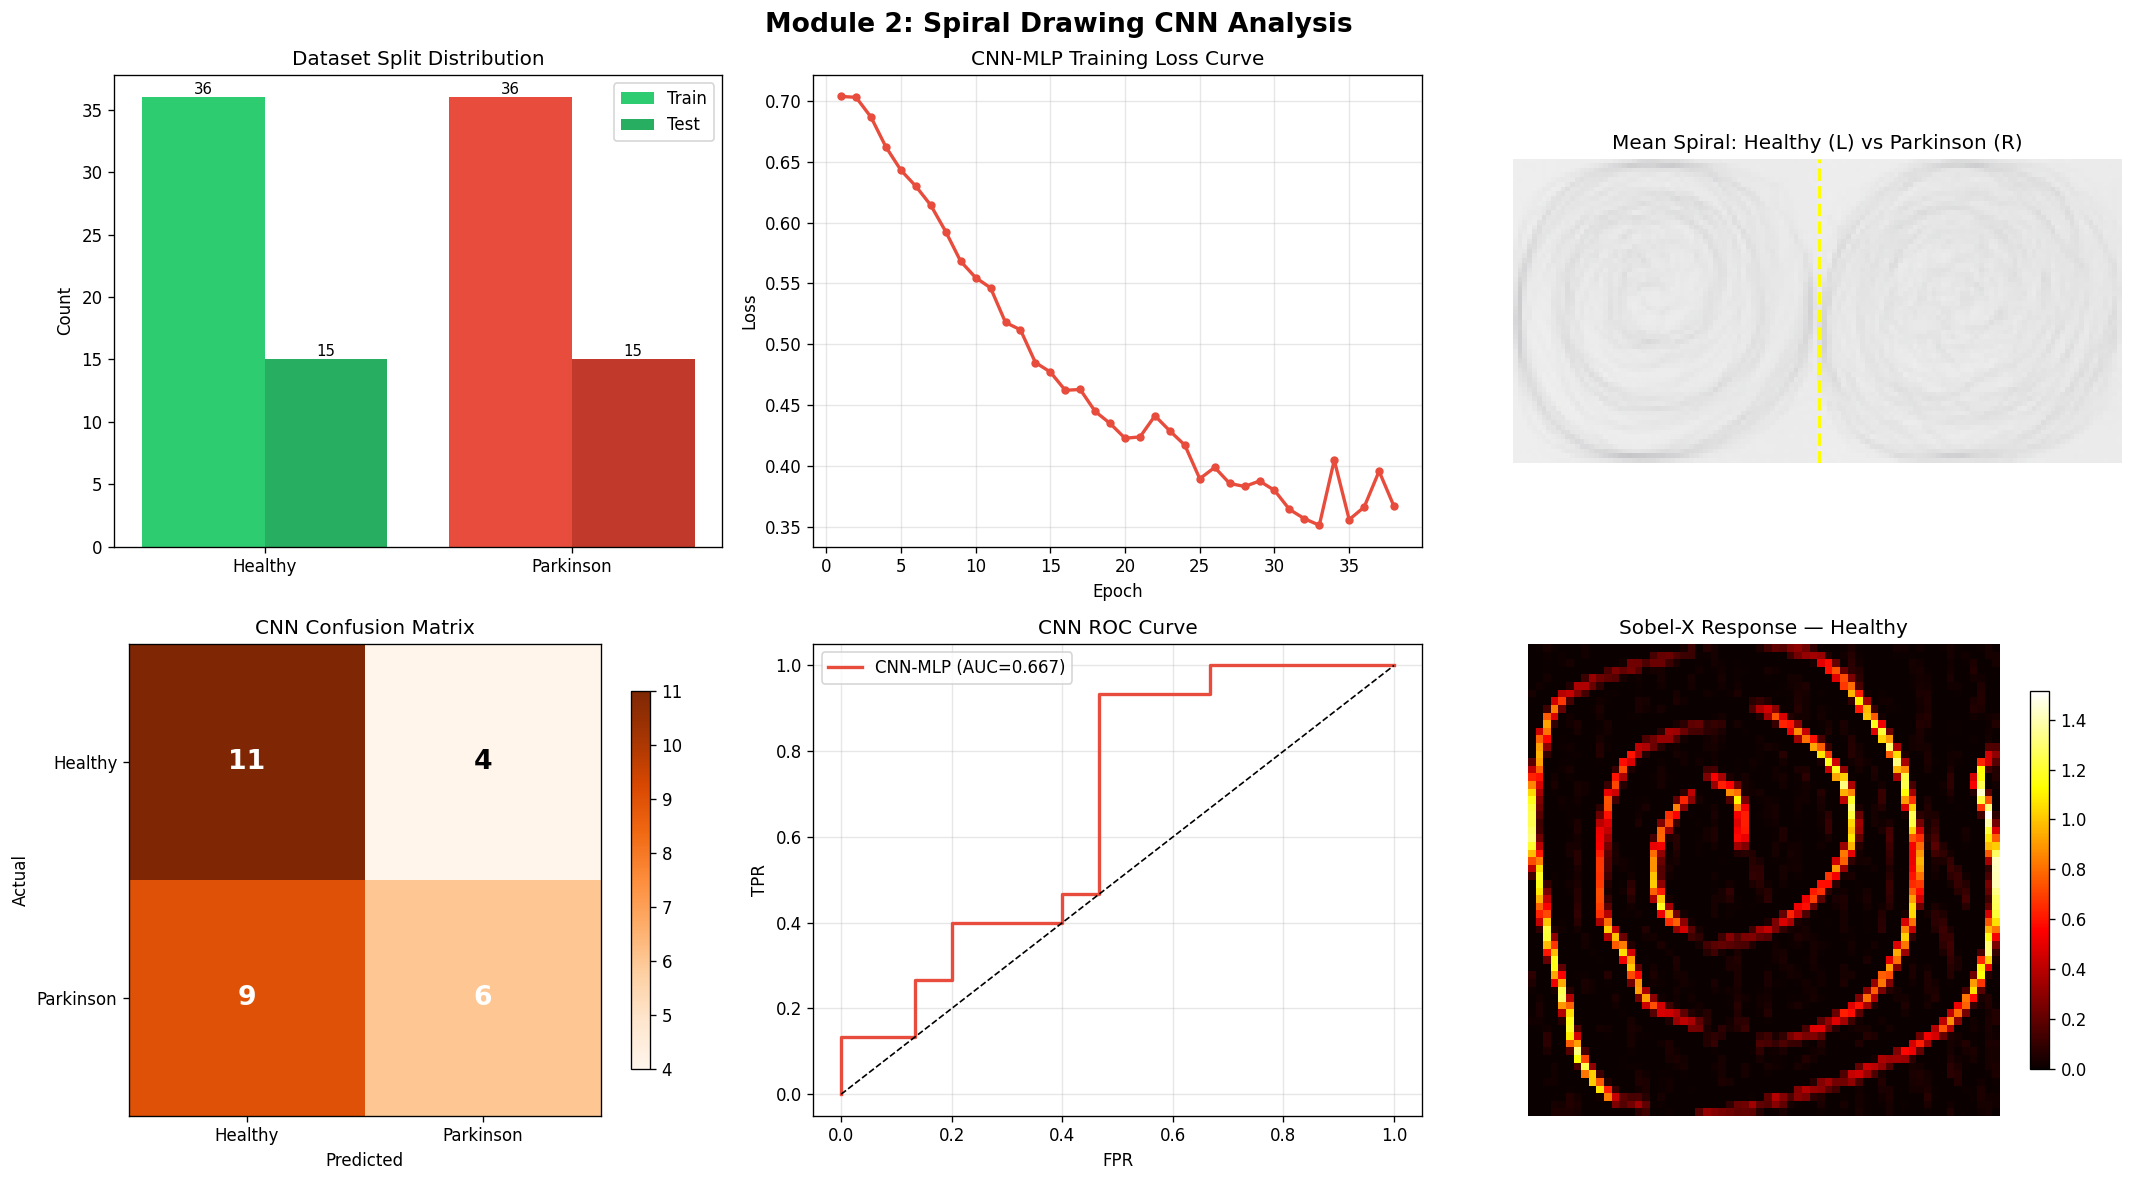

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Module 2: Spiral Drawing CNN Analysis", fontsize=16, fontweight="bold")

# ── Dataset split distribution ────────────────────────────────────────────────
ax = axes[0, 0]
counts_tr = np.bincount(y_img_train)
counts_te = np.bincount(y_img_test)
x_ = np.arange(2)
ax.bar(x_ - 0.2, counts_tr, 0.4, label="Train", color=["#2ecc71", "#e74c3c"])
ax.bar(x_ + 0.2, counts_te, 0.4, label="Test",  color=["#27ae60", "#c0392b"])
ax.set_xticks(x_); ax.set_xticklabels(["Healthy", "Parkinson"])
ax.set_title("Dataset Split Distribution")
ax.set_ylabel("Count"); ax.legend()
for xi, v in enumerate(counts_tr):
    ax.text(xi - 0.2, v + 0.3, str(v), ha="center", fontsize=9)
for xi, v in enumerate(counts_te):
    ax.text(xi + 0.2, v + 0.3, str(v), ha="center", fontsize=9)

# ── Training loss curve ───────────────────────────────────────────────────────
ax = axes[0, 1]
ax.plot(range(1, len(cnn_loss_hist)+1), cnn_loss_hist, "-o",
        color="#e74c3c", lw=2, markersize=4)
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
ax.set_title("CNN-MLP Training Loss Curve")
ax.grid(alpha=0.3)

# ── Mean spiral: Healthy vs Parkinson ─────────────────────────────────────────
ax = axes[0, 2]
avg_h = X_img_train[y_img_train == 0].mean(axis=0)
avg_p = X_img_train[y_img_train == 1].mean(axis=0)
combined = np.concatenate([avg_h, avg_p], axis=1)
ax.imshow(np.clip(combined, 0, 1))
ax.axvline(x=64, color="yellow", lw=2, linestyle="--")
ax.set_title("Mean Spiral: Healthy (L) vs Parkinson (R)")
ax.axis("off")

# ── Confusion matrix ──────────────────────────────────────────────────────────
ax = axes[1, 0]
cm_cnn = confusion_matrix(y_img_test, y_cnn_pred)
im = ax.imshow(cm_cnn, cmap="Oranges")
ax.set_xticks([0,1]); ax.set_yticks([0,1])
ax.set_xticklabels(["Healthy","Parkinson"])
ax.set_yticklabels(["Healthy","Parkinson"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("CNN Confusion Matrix")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm_cnn[i,j]), ha="center", va="center",
                fontsize=16, fontweight="bold",
                color="white" if cm_cnn[i,j] > cm_cnn.max()/2 else "black")
plt.colorbar(im, ax=ax, shrink=0.8)

# ── ROC curve ─────────────────────────────────────────────────────────────────
ax = axes[1, 1]
fpr_c, tpr_c, _ = roc_curve(y_img_test, y_cnn_prob)
ax.plot(fpr_c, tpr_c, color="#e74c3c", lw=2, label=f"CNN-MLP (AUC={cnn_auc:.3f})")
ax.plot([0,1],[0,1],"k--",lw=1)
ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
ax.set_title("CNN ROC Curve")
ax.legend(); ax.grid(alpha=0.3)

# ── Filter response visualisation ─────────────────────────────────────────────
ax = axes[1, 2]
filter_names = ["Sobel-X","Sobel-Y","Laplacian","Diagonal",
                "Anti-diag","Horiz Edge","Vert Edge","Sharpen"]
# Show mean filter response per class for first 2 filters
sample_h = X_img_train[y_img_train == 0][0].mean(axis=2)
sample_p = X_img_train[y_img_train == 1][0].mean(axis=2)

filters_arr = np.array([
    [[-1,0,1],[-2,0,2],[-1,0,1]],
    [[-1,-2,-1],[0,0,0],[1,2,1]],
], dtype=np.float32)

responses = []
for sample, lbl in [(sample_h, "Healthy"), (sample_p, "Parkinson")]:
    H, W = sample.shape
    conv = np.zeros((H-2, W-2))
    for di in range(3):
        for dj in range(3):
            conv += sample[di:H-2+di, dj:W-2+dj] * filters_arr[0][di,dj]
    responses.append((lbl, np.maximum(0, conv)))

im0 = ax.imshow(responses[0][1], cmap="hot")
ax.set_title(f"Sobel-X Response — {responses[0][0]}")
ax.axis("off")
plt.colorbar(im0, ax=ax, shrink=0.8)

plt.tight_layout()
plt.show()


---
## 📈 Module 3 — Final Summary Dashboard

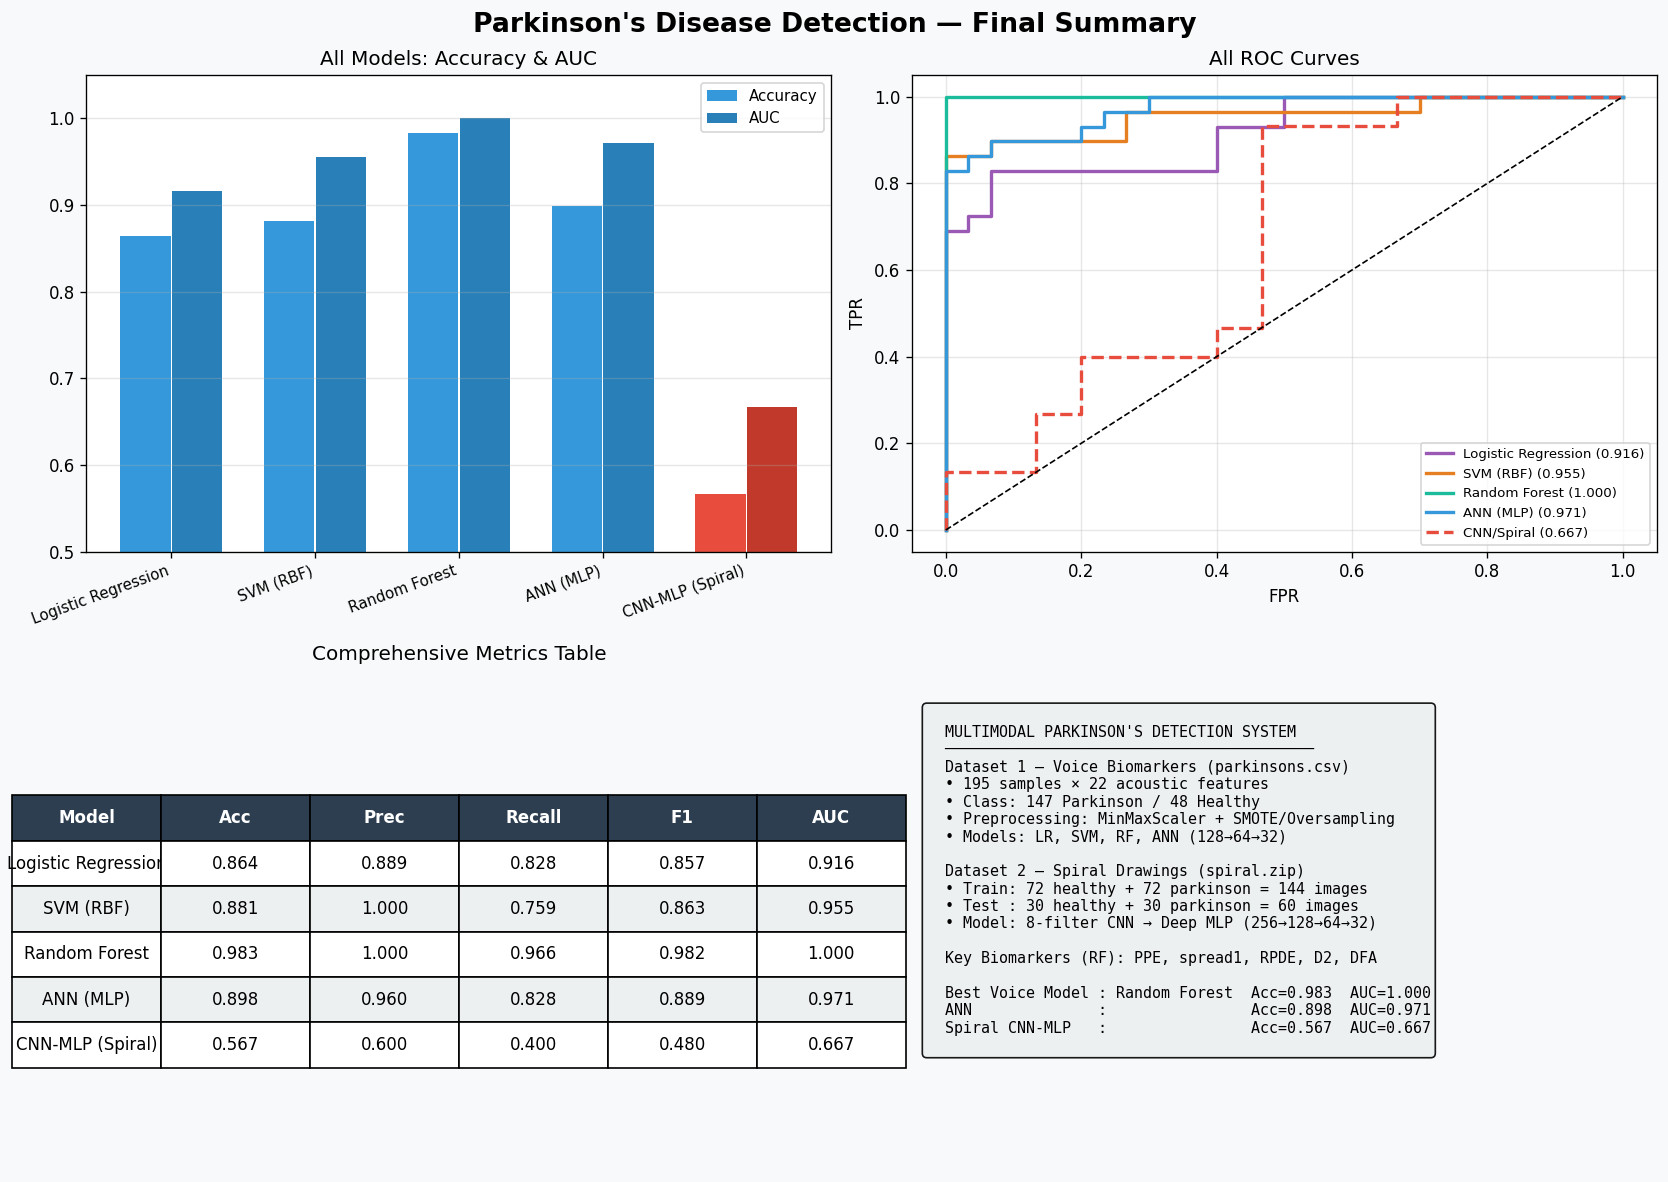

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Parkinson's Disease Detection — Final Summary",
             fontsize=16, fontweight="bold")
fig.patch.set_facecolor("#f8f9fa")

# ── All models: Accuracy & AUC ────────────────────────────────────────────────
ax = axes[0, 0]
all_names = list(ml_results.keys()) + ["CNN-MLP (Spiral)"]
all_accs  = [ml_results[m]["acc"] for m in ml_results] + [cnn_acc]
all_aucs  = [ml_results[m]["auc"] for m in ml_results] + [cnn_auc]
x_ = np.arange(len(all_names))
ax.bar(x_ - 0.18, all_accs, 0.35, label="Accuracy",
       color=["#3498db"]*4 + ["#e74c3c"])
ax.bar(x_ + 0.18, all_aucs, 0.35, label="AUC",
       color=["#2980b9"]*4 + ["#c0392b"])
ax.set_xticks(x_)
ax.set_xticklabels(all_names, rotation=20, ha="right", fontsize=9)
ax.set_ylim(0.5, 1.05)
ax.set_title("All Models: Accuracy & AUC")
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.3)

# ── All ROC curves ────────────────────────────────────────────────────────────
ax = axes[0, 1]
for (name, res), c in zip(ml_results.items(),
                          ["#9b59b6","#e67e22","#1abc9c","#3498db"]):
    fpr_, tpr_, _ = roc_curve(y_test, res["y_prob"])
    ax.plot(fpr_, tpr_, label=f"{name} ({res['auc']:.3f})", color=c, lw=2)
ax.plot(fpr_c, tpr_c, "--", color="#e74c3c",
        label=f"CNN/Spiral ({cnn_auc:.3f})", lw=2)
ax.plot([0,1],[0,1],"k--",lw=1)
ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
ax.set_title("All ROC Curves")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

# ── Metrics table ─────────────────────────────────────────────────────────────
ax = axes[1, 0]
ax.axis("off")
table_data = []
for name in ml_results:
    r   = ml_results[name]
    cm_ = confusion_matrix(y_test, r["y_pred"])
    tp, fn, fp = cm_[1,1], cm_[1,0], cm_[0,1]
    prec   = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    f1_    = 2 * prec * recall / (prec + recall + 1e-9)
    table_data.append([name, f"{r['acc']:.3f}", f"{prec:.3f}",
                       f"{recall:.3f}", f"{f1_:.3f}", f"{r['auc']:.3f}"])
cm_c_ = confusion_matrix(y_img_test, y_cnn_pred)
tp_c, fn_c, fp_c = cm_c_[1,1], cm_c_[1,0], cm_c_[0,1]
prec_c   = tp_c / (tp_c + fp_c + 1e-9)
recall_c = tp_c / (tp_c + fn_c + 1e-9)
f1_c     = 2*prec_c*recall_c / (prec_c + recall_c + 1e-9)
table_data.append(["CNN-MLP (Spiral)", f"{cnn_acc:.3f}", f"{prec_c:.3f}",
                   f"{recall_c:.3f}", f"{f1_c:.3f}", f"{cnn_auc:.3f}"])

tbl = ax.table(cellText=table_data,
               colLabels=["Model","Acc","Prec","Recall","F1","AUC"],
               loc="center", cellLoc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(10)
tbl.scale(1.2, 2.0)
for (row, col), cell in tbl.get_celld().items():
    if row == 0:
        cell.set_facecolor("#2c3e50")
        cell.set_text_props(color="white", fontweight="bold")
    elif row % 2 == 0:
        cell.set_facecolor("#ecf0f1")
ax.set_title("Comprehensive Metrics Table", fontsize=12, pad=20)

# ── Summary text ──────────────────────────────────────────────────────────────
ax = axes[1, 1]
ax.axis("off")
summary = f"""
  MULTIMODAL PARKINSON'S DETECTION SYSTEM
  ─────────────────────────────────────────
  Dataset 1 — Voice Biomarkers (parkinsons.csv)
  • 195 samples × 22 acoustic features
  • Class: 147 Parkinson / 48 Healthy
  • Preprocessing: MinMaxScaler + SMOTE/Oversampling
  • Models: LR, SVM, RF, ANN (128→64→32)

  Dataset 2 — Spiral Drawings (spiral.zip)
  • Train: 72 healthy + 72 parkinson = 144 images
  • Test : 30 healthy + 30 parkinson = 60 images
  • Model: 8-filter CNN → Deep MLP (256→128→64→32)

  Key Biomarkers (RF): PPE, spread1, RPDE, D2, DFA

  Best Voice Model : Random Forest  Acc={ml_results['Random Forest']['acc']:.3f}  AUC={ml_results['Random Forest']['auc']:.3f}
  ANN              :                Acc={acc_ann:.3f}  AUC={auc_ann:.3f}
  Spiral CNN-MLP   :                Acc={cnn_acc:.3f}  AUC={cnn_auc:.3f}
"""
ax.text(0.02, 0.97, summary, transform=ax.transAxes,
        fontsize=9, va="top", fontfamily="monospace",
        bbox=dict(boxstyle="round", facecolor="#ecf0f1", alpha=0.9))

plt.tight_layout()
plt.show()


## ✅ Final Results

In [14]:
print("=" * 60)
print("  FINAL RESULTS SUMMARY")
print("=" * 60)
print("\nVoice Biomarker Models (parkinsons.csv):")
for name in ml_results:
    r = ml_results[name]
    print(f"  {name:<22} Acc={r['acc']:.4f}  AUC={r['auc']:.4f}")
print("\nSpiral Drawing CNN (spiral.zip):")
print(f"  {'CNN-MLP':<22} Acc={cnn_acc:.4f}  AUC={cnn_auc:.4f}")
print("\nPipeline complete ✅")


  FINAL RESULTS SUMMARY

Voice Biomarker Models (parkinsons.csv):
  Logistic Regression    Acc=0.8644  AUC=0.9161
  SVM (RBF)              Acc=0.8814  AUC=0.9552
  Random Forest          Acc=0.9831  AUC=1.0000
  ANN (MLP)              Acc=0.8983  AUC=0.9713

Spiral Drawing CNN (spiral.zip):
  CNN-MLP                Acc=0.5667  AUC=0.6667

Pipeline complete ✅
